<a href="https://colab.research.google.com/github/eileen795/MSSP-6070/blob/main/exercise_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import geopandas as gpd

url1 = "https://raw.githubusercontent.com/eileen795/MSSP-6070/main/Modules/week11/CA_Legislative_Districts.csv"
url2 = "https://raw.githubusercontent.com/eileen795/MSSP-6070/main/Modules/week11/california-congressional-districts.geojson"

df = pd.read_csv(url1)
gdf = gpd.read_file(url2)

display(df.head())
display(gdf.head())

,OBJECTID,ID,AREA,DISTRICT,MEMBERS,NAME,POPULATION,CVAP_19,HSP_CVAP_1,DOJ_NH_BLK,...,MULTIPLE_F,F_CVAP_19,F_HSP_CVAP,F_DOJ_NH_B,F_DOJ_NH_A,F_NH_WHT_C,DISTRICT_L,DISTRICT_N,SHAPE_Length,SHAPE_Area
0,1,1,27014.63,1,1,MTCAP,760066,549203,77031,10923,...,1|0,0.7226,0.1403,0.0199,0.0475,0.7507,1|0%,1,2.633906e+06,1.222952e+11
1,2,2,560.65,10,1,STANI,760066,503249,67160,26317,...,10|0,0.6621,0.1335,0.0523,0.1713,0.6220,10|0%,10,3.582890e+05,2.336909e+09
2,3,3,226.43,11,1,COCO,760067,568460,61171,33907,...,11|1,0.7479,0.1076,0.0596,0.3160,0.5006,11|0%,11,2.111932e+05,9.404054e+08
3,4,4,141.25,12,1,SF,760065,510978,74038,101894,...,12|-1,0.6723,0.1449,0.1994,0.2139,0.4169,12|-0%,12,1.246786e+05,5.869476e+08
4,5,5,6346.92,13,1,OKLND,760065,393416,197645,16042,...,13|-1,0.5176,0.5024,0.0408,0.0621,0.3708,13|-0%,13,1.186868e+06,2.578115e+10


,Name,description,descriptio,geometry
0,01,None,,"MULTIPOLYGON (((-120.07192 41.99495, -120.0010..."
1,02,None,,"MULTIPOLYGON (((-123.69821 41.81719, -123.6967..."
2,03,None,,"MULTIPOLYGON (((-121.667 39.30511, -121.63015 ..."
3,04,None,,"MULTIPOLYGON (((-120.37731 37.61679, -120.3823..."
4,05,None,,"MULTIPOLYGON (((-122.16384 38.64288, -122.1659..."


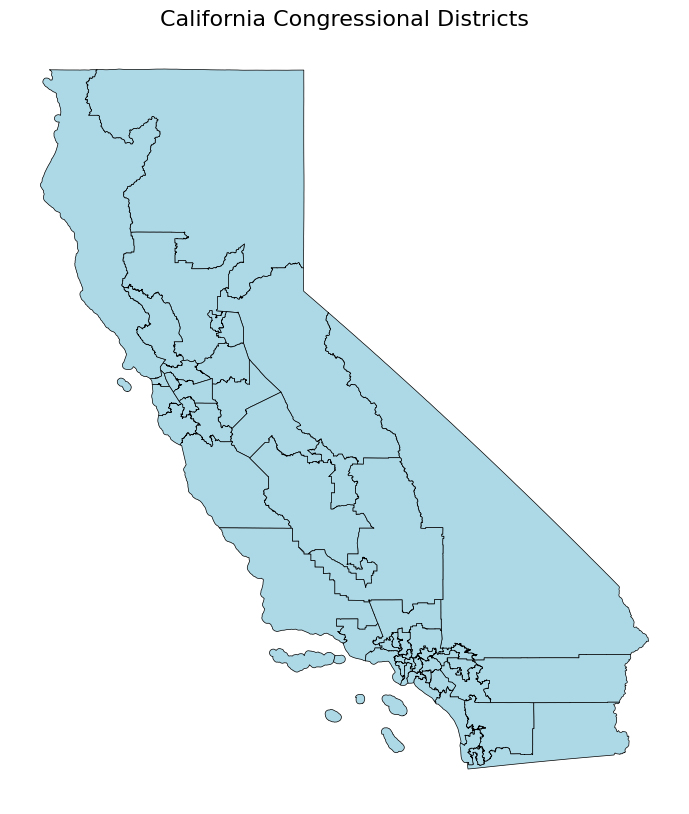

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

gdf.plot(
    ax=ax,
    edgecolor='black',
    facecolor='lightblue',
    linewidth=0.5)

ax.set_title(
    'California Congressional Districts',
    fontsize=16)

ax.set_axis_off()

plt.show()


In [10]:
# Check district identifiers
print("GeoJSON district names:")
print(gdf['Name'].unique())

print("\nCSV district numbers:")
print(df['DISTRICT'].unique())

GeoJSON district names:
['01' '02' '03' '04' '05' '06' '07' '08' '09' '10' '11' '12' '37' '13'
 '14' '15' '16' '17' '18' '19' '20' '21' '22' '23' '24' '25' '26' '27'
 '28' '29' '30' '31' '32' '33' '34' '35' '36' '38' '39' '40' '41' '42'
 '43' '46' '47' '44' '45' '48' '49' '50' '51' '52' '53']

CSV district numbers:
[ 1 10 11 12 13 14 15 16 17 18 19  2 20 21 22 23 24 25 26 27 28 29  3 30
 31 32 33 34 35 36 37 38 39  4 40 41 42 43 44 45 46 47 48 49  5 50 51 52
  6  7  8  9]


In [11]:
# Convert district names to integers
gdf['DISTRICT'] = gdf['Name'].astype(int)

# Merge population data
merged_gdf = gdf.merge(
    df[['DISTRICT', 'POPULATION']],
    on='DISTRICT',
    how='left')

# Check the result
display(merged_gdf[['Name', 'DISTRICT', 'POPULATION']].head())

,Name,DISTRICT,POPULATION
0,01,1,760066.0
1,02,2,760067.0
2,03,3,760065.0
3,04,4,760065.0
4,05,5,760065.0


In [12]:
print("Total districts:", len(merged_gdf))
print("Missing population:", merged_gdf['POPULATION'].isna().sum())

display(
    merged_gdf[merged_gdf['POPULATION'].isna()])

Total districts: 53
Missing population: 1


,Name,description,descriptio,geometry,DISTRICT,POPULATION
52,53,None,,"MULTIPOLYGON (((-117.18538 32.75873, -117.1788...",53,NaN


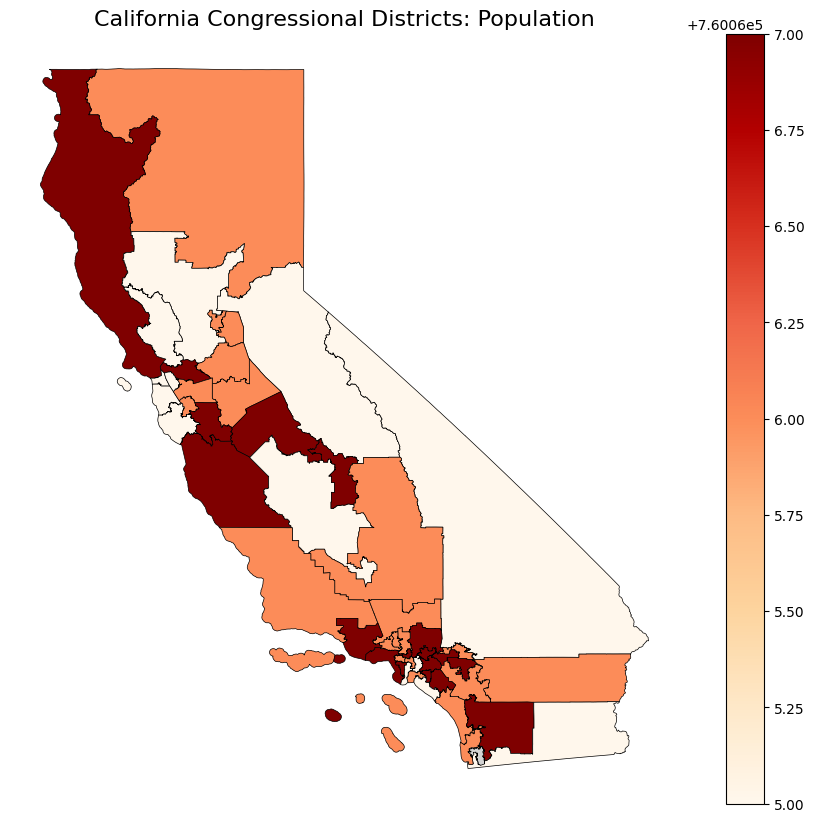

In [13]:
fig, ax = plt.subplots(figsize=(12, 10))

merged_gdf.plot(
    column='POPULATION',
    cmap='OrRd',
    legend=True,
    edgecolor='black',
    linewidth=0.5,
    missing_kwds={
        'color': 'lightgrey',
        'label': 'No population data'},
    ax=ax)

ax.set_title(
    'California Congressional Districts: Population',
    fontsize=16)

ax.set_axis_off()

plt.show()
